In [1]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import bootstrap

In [2]:
def ranked_probability_scores(observations, predictions):
    
    N = len(observations)
    rps = np.zeros(N)
    
    for i in range(N):
        
        observation_prob = np.array([0,0,0])
        observation_prob[observations[i]] = 1
            
        rps[i] = 1/2*( (np.cumsum(predictions[i])-np.cumsum(observation_prob))**2 ).sum()

    return rps

In [3]:
df_features = pd.read_csv('features/features_NE_week4.csv')
df_target = pd.read_csv('targets/northern_temperature_terc_cat_new.csv')

In [4]:
df_features['time'] = pd.to_datetime(df_features['time'])
df_features = df_features.set_index('time')

df_target['time'] = pd.to_datetime(df_target['time'])
df_target = df_target.set_index('time')

In [5]:
y_train = df_target[df_target.index < "2010-07"].values[:,0]
y_test = df_target[df_target.index >= "2010-07"].values[:,0]

In [6]:
drop = ['snow_depth', 'nino3.4_index', 'sea_ice_arctic', 'soil_moist_upper', 'sea_ice_baka', 'MJO_phase', 'soil_moist_lower']
df_features_sel = df_features.drop(columns=drop)
len(df_features_sel.columns)

2

In [7]:
X_train = df_features_sel[df_features_sel.index < "2010-07"].values
X_test = df_features_sel[df_features_sel.index >= "2010-07"].values

In [8]:
classifier = RandomForestClassifier(n_estimators=1000, criterion='entropy', max_depth=None, min_samples_leaf=1500, random_state=42)
classifier.fit(X_train, y_train)

y_pred = classifier.predict_proba(X_test)
rps = ranked_probability_scores(y_test, y_pred)

y_climpred = 1/3*np.ones((15*84, 3))
rps_clim = ranked_probability_scores(y_test, y_climpred)

print(rps.mean())
print(rps_clim.mean())

0.21634443143641005
0.2202380952380953


In [9]:
rpss = 100*(1-rps.mean()/rps_clim.mean())
print(rpss)

1.767933834278701


In [10]:
rps_valid = 0.2209801631629251
rpss_valid = 100*(1-rps_valid/2*9)
print(rpss_valid)

0.5589265766837048


In [11]:
rps_valid_clim = 0.2238247519793771
rpss_valid_unbiased = 100*(1-rps_valid/rps_valid_clim)
print(rpss_valid_unbiased)

1.2709000194554454


In [11]:
drps_valid = np.array([-0.01230193,  0.0172821 ,  0.00085214,  0.02061503, -0.00950847,
       -0.01695335,  0.02342497,  0.00039845, -0.00824421,  0.00034597,
       -0.01850278,  0.00184495,  0.0048166 , -0.01674797,  0.00642492,
        0.0236884 ,  0.00369388, -0.01529454,  0.02080703,  0.01829802,
       -0.00916115, -0.00038825,  0.00611294,  0.00725559, -0.00891274,
       -0.01207907,  0.0005674 ,  0.0072209 ,  0.00263367, -0.00163469,
       -0.00983547,  0.01647173,  0.02176433,  0.0023233 ,  0.01774795,
       -0.0188184 , -0.02964063,  0.00848515,  0.02567992,  0.01842845,
       -0.00280036,  0.01306593,  0.01478789,  0.00645885, -0.00601491,
        0.00044483, -0.00415278, -0.01104322,  0.00268386,  0.00058901,
        0.00330473,  0.00332405,  0.01205863, -0.00925508,  0.01916056,
       -0.001164  ,  0.00090141,  0.01817929, -0.00714141,  0.01490477])

In [12]:
print(drps_valid[:28].mean())
print(drps_valid[28:].mean())

0.0012698153571428573
0.0038092925


In [32]:
rps_ann = rps.reshape((15,84)).mean(axis=1)
rps_clim_ann = rps_clim.reshape((15,84)).mean(axis=1)

In [33]:
def skill_score(score, ref_score, axis=-1):
    mean = np.mean(score, axis=axis)
    mean_ref = np.mean(ref_score, axis=axis)
    return 1 - mean/mean_ref

In [34]:
skill_score(rps_ann, rps_clim_ann)

np.float64(0.01767933834278712)

In [35]:
res = bootstrap((rps_ann, rps_clim_ann), skill_score, paired=True, confidence_level=0.90, rng=42)

In [36]:
res.confidence_interval

ConfidenceInterval(low=np.float64(-0.0001281690872399999), high=np.float64(0.03948376668830846))

In [19]:
regions = ['week 3', 'week 4', 'week 5']
skills = np.array([0.02675837238769463,0.01767933834278712,0.012918621604410485])*100
lower =  np.array([0.0022343107941105865,-0.0001281690872399999,-0.00499034616567212])*100
upper =  np.array([0.05288596322951867,0.03948376668830846,0.03090853492854605])*100

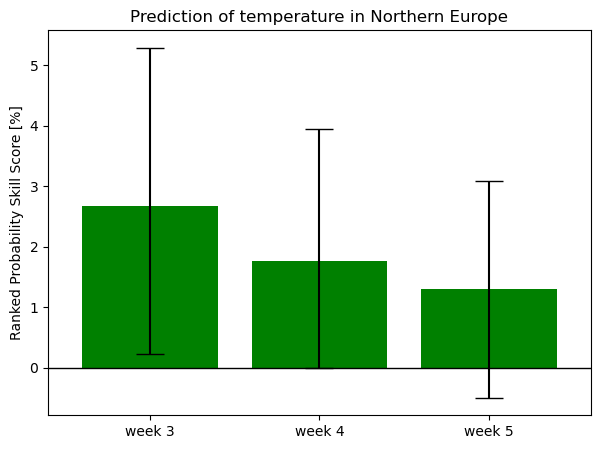

In [20]:
fig, ax = plt.subplots(figsize=(7,5))

ax.bar(regions, skills, yerr=np.stack((skills-lower, upper-skills)), capsize=10, color='green') 
ax.hlines(0, -0.6, 2.6, 'k', linewidths=1)
ax.set_xlim((-0.6, 2.6))
ax.set_ylabel('Ranked Probability Skill Score [%]')
ax.set_title('Prediction of temperature in Northern Europe')
plt.savefig('NE_temp_terc_weeks345_bars.pdf', bbox_inches = 'tight')

0.005893212966337416


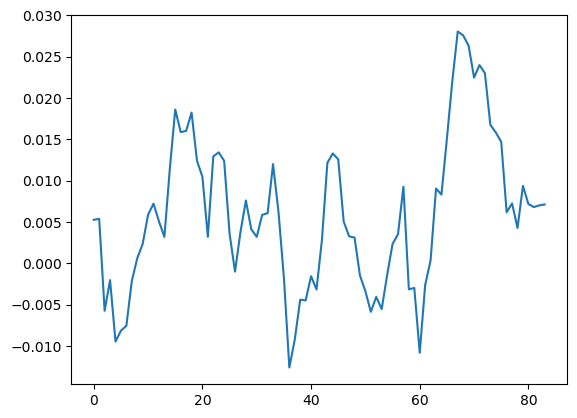

In [20]:
drps_cyc = rps_clim.reshape((15,84)).mean(axis=0) - rps.reshape((15,84)).mean(axis=0)
print(drps_cyc.mean())
plt.plot(drps_cyc)

In [21]:
drps_ann = rps_clim.reshape((15,84)).mean(axis=1) - rps.reshape((15,84)).mean(axis=1)
print(drps_ann.mean())

0.00589321296633745


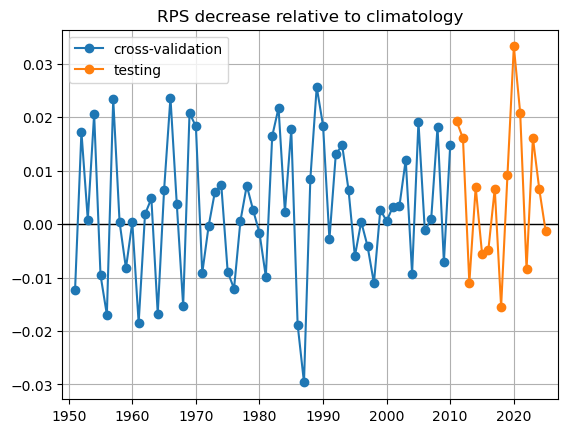

In [23]:
plt.hlines(0, 1949, 2027,'k', linewidths=1)
plt.plot(range(1951,2011), drps_valid, 'o-', label='cross-validation')
plt.plot(range(2011,2026), drps_ann, 'o-', label='testing')
plt.legend()
plt.title('RPS decrease relative to climatology')
plt.xlim((1949, 2027))
plt.grid()
plt.savefig('NE_temp_terc_timeseries.png', bbox_inches = 'tight')

In [12]:
lofo_rps = np.array([0.2219536329464104, 0.2222664988401327])
lofo_importances = lofo_rps - rps_valid
df_importances = pd.Series(
    lofo_importances, index=df_features_sel.columns
)

Text(0.5, 0, 'Increase in RPS')

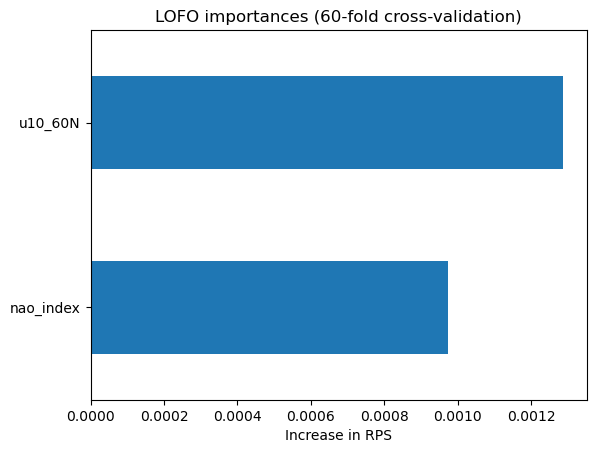

In [13]:
ax = df_importances.plot.barh()
ax.set_title("LOFO importances (60-fold cross-validation)")
ax.set_xlabel("Increase in RPS")
#plt.savefig('NE_temp_terc_lofo_valid.png', bbox_inches = 'tight')

In [14]:
lofo_rps_test = np.zeros(2)
for i in range(2):

    leave_out = df_features_sel.columns[i]
    df_features_new = df_features_sel.drop(columns=leave_out)
    X_train = df_features_new[df_features_new.index < "2010-07"].values
    X_test = df_features_new[df_features_new.index >= "2010-07"].values
    
    classifier = RandomForestClassifier(n_estimators=1000, criterion='entropy', max_depth=None, min_samples_leaf=1500, random_state=42)
    classifier.fit(X_train, y_train)

    y_pred = classifier.predict_proba(X_test)
    rps = ranked_probability_scores(y_test, y_pred)
    lofo_rps_test[i] = rps.mean()

In [15]:
lofo_importances_test = lofo_rps_test - 0.21634443143641005
df_importances_test = pd.Series(
    lofo_importances_test, index=df_features_sel.columns
)

Text(0.5, 0, 'Increase in RPS')

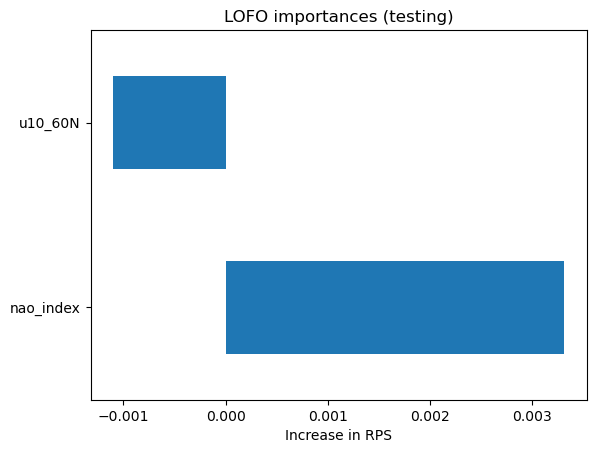

In [16]:
ax = df_importances_test.plot.barh()
ax.set_title("LOFO importances (testing)")
ax.set_xlabel("Increase in RPS")
#plt.savefig('NE_temp_terc_lofo_test.png', bbox_inches = 'tight')

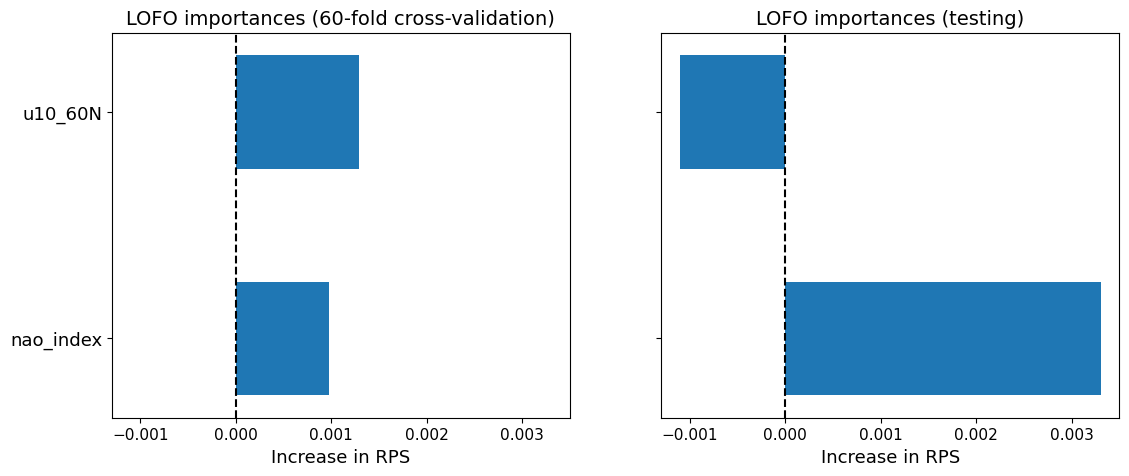

In [18]:
fig, ax = plt.subplots(1,2,figsize=(13,5))

ax[0].barh(df_importances.index, df_importances.values, 0.5)
ax[0].tick_params('y',labelsize=13)
ax[0].tick_params('x',labelsize=11)
ax[0].set_title("LOFO importances (60-fold cross-validation)", fontsize=14)
ax[0].set_xlabel("Increase in RPS", fontsize=13)
ax[0].set_xlim((-0.0013, 0.0035))
ax[0].vlines(0, -0.35, 1.35, 'k', '--')
ax[0].set_ylim((-0.35, 1.35))

ax[1].barh(df_importances_test.index, df_importances_test.values, 0.5, tick_label=['',''])
ax[1].tick_params('x',labelsize=11)
ax[1].set_title("LOFO importances (testing)", fontsize=14)
ax[1].set_xlabel("Increase in RPS", fontsize=13)
ax[1].set_xlim((-0.0013, 0.0035))
ax[1].vlines(0, -0.35, 1.35, 'k', '--')
ax[1].set_ylim((-0.35, 1.35))

plt.savefig('NE_temp_terc_lofo_week4.pdf', bbox_inches = 'tight')